In [1]:
import warnings
warnings.filterwarnings('ignore')

import xarray as xr
from glob import glob
import numpy as np
from tqdm import tqdm
import pandas as pd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import gsw
import cmocean.cm as cmo
import pickle

from utils import get_shelf_edge, make_map, subplots_structure, add_observation_locations
from geostrophic_utils import (_plot_single_day, get_angle, compute_geostrophic_velocity,
                              _plot_one_track, plot_eddies, daily_geostrophic_current,
                              build_transect, ultimate_plot_one_track, plot_timeseries2)

from geostrophic_utils import load_satellites, plot_4days_tracks,  get_uv2

# import sys
# sys.path.insert(0, '/home/danilo/phd/repos/pytools')
# from pytools.sandbox.sandbox import get_uv2

In [2]:
import matplotlib as mpl

mpl.rcParams['xtick.labelsize'] = 12
mpl.rcParams['ytick.labelsize'] = 12

In [3]:
import dask
from dask.distributed import Client, LocalCluster

cluster = LocalCluster(n_workers=5) #number of cores
client = Client(cluster) # go check dask dashboard

In [4]:
# extent =[360-47.5, 360-37.5, -28, -20.62] # max lat fits the gebco data I have for sheld egde contour
extent = [-45, -41, -26, -22]
zoomed_extent= [-45, -39, -27, -22]

# set relative path to the source file
datadir = './../data/aviso_alongtracks/sanagu2022'
savedir = './../figures/aviso/alongtracks/sanagu2022/march_evolution'

timerange = [pd.to_datetime('2022-03-01'), 
             pd.to_datetime('2022-04-01')]

In [5]:
# loading netcdf files (gridded SSH from aviso, mesoscale eddy ATLAS and 
# alongtrack from several satellites

# loading gridded aviso ssh
ds_aviso = xr.open_dataset(f"{datadir}/../../sanagu2022/dataset-duacs-nrt-global-merged-allsat-phy-l4_20220101_20220401.nc")

# loading eddies
ds_locs = xr.open_dataset(f"{datadir}/../../sanagu2022/eddies_sanagu2022_daily.nc")

fnames = glob(f"{datadir}/*")
satellite = [fname.split("_")[3] for fname in fnames]
usatellites = list(np.unique(satellite))

In [6]:
bathy = xr.open_dataset('../data/gebco_2019.nc')
# rename variables for a padronization
bathy = bathy.rename({'elevation': 'depth'})
bathy = bathy.where(bathy['depth'] < 0, drop=True)

# regional selection (for both dataset loaded)
lon_lower, lon_upper = zoomed_extent[0], zoomed_extent[1] #-50, -40
lat_lower, lat_upper = zoomed_extent[2], zoomed_extent[3] #-29, -23

# bathymetry
bathy = bathy.sel(lon=slice(lon_lower, lon_upper),
                lat=slice(lat_lower, lat_upper))

In [7]:
# loading ARGO profiles locations
ds_argo = xr.open_dataset('../data/argo/argo_profiles_all.nc')

# loading SANAGU dataset
locs = pd.read_csv(f"/home/danilo/phd/thesis/chapter_colab/scripts/section-ctd_dalton/data/umassd2/locations.csv", index_col=0)

In [8]:
try:
    tracks = pickle.load(open("satellites_geostrophic_alongtrack.pkl", "rb"))
except:
    days = [pd.to_datetime('2022-02-16'),
            pd.to_datetime('2022-02-21'), 
            pd.to_datetime('2022-03-07'), 
            pd.to_datetime('2022-03-27')]

    ds_list = load_satellites(days, datadir)

    tracks = {
     '2022-02-16': {
        'alg': {'track': [645], 'cycle': [158], 'inclination': 'negative', 'data': None, 'fix': False, 'fix_stickplot': False},
        'c2n': {'track': [439], 'cycle': [222], 'inclination': 'positive', 'data': None, 'fix': False, 'fix_stickplot': False},
        'h2b': {'track': [57], 'cycle': [87], 'inclination': 'negative', 'data': None, 'fix': False, 'fix_stickplot': False},
        },
     '2022-02-21': {
        'h2b': {'track': [195], 'cycle': [87], 'inclination': 'negative', 'data': None, 'fix': False, 'fix_stickplot': False},
        's3a': {'track': [332], 'cycle': [82], 'inclination': 'positive', 'data': None, 'fix': False, 'fix_stickplot': False},
        's6a': {'track': [126], 'cycle': [47], 'inclination': 'negative', 'data': None, 'fix': True, 'fix_stickplot': False}
        },
     '2022-02-26': {
        's6a': {'track': [239], 'cycle': [47], 'inclination': 'positive', 'data': None, 'fix': True, 'fix_stickplot': False}
        },
     '2022-03-07': {
          's3b': {'track': [446], 'cycle': [63], 'inclination': 'positive', 'data': None, 'fix': False, 'fix_stickplot': False},
          'alg': {'track': [187], 'cycle': [159], 'inclination': 'negative', 'data': None, 'fix': False, 'fix_stickplot': False},
          'c2n': {'track': [265], 'cycle': [223], 'inclination': 'negative', 'data': None, 'fix': False, 'fix_stickplot': False}
         },
     '2022-03-27': {
          's3b': {'track': [233], 'cycle': [64], 'inclination': 'negative', 'fix': False, 'fix_stickplot': True},
          's6a': {'track': [239], 'cycle': [50], 'inclination': 'positive', 'fix': True, 'fix_stickplot': True}
     }
    }

    # adding information based on the dataset itself, like inclination angle and the dataset
    for t,day in enumerate(tracks):
        ds = ds_list[str(t)]

        for k in tracks[day]:
            dsi = ds[k]

            for track,cycle in zip(tracks[day][k]['track'], tracks[day][k]['cycle']):
                dsplot = dsi.where(dsi['track'] == track, drop=True)
                dsplot = dsplot.where(dsplot['cycle'] == cycle, drop=True)

                # identify the angle of the track relative to the geographical north
                theta = get_angle(dsplot['longitude'].values, dsplot['latitude'].values)

                tracks[day][k]['data'] = dsplot
                tracks[day][k]['theta'] = np.abs(theta) if tracks[day][k]['inclination'] == 'positive' else theta
                
    with open("satellites_geostrophic_alongtrack.pkl", "wb") as f:
        pickle.dump(tracks, f)

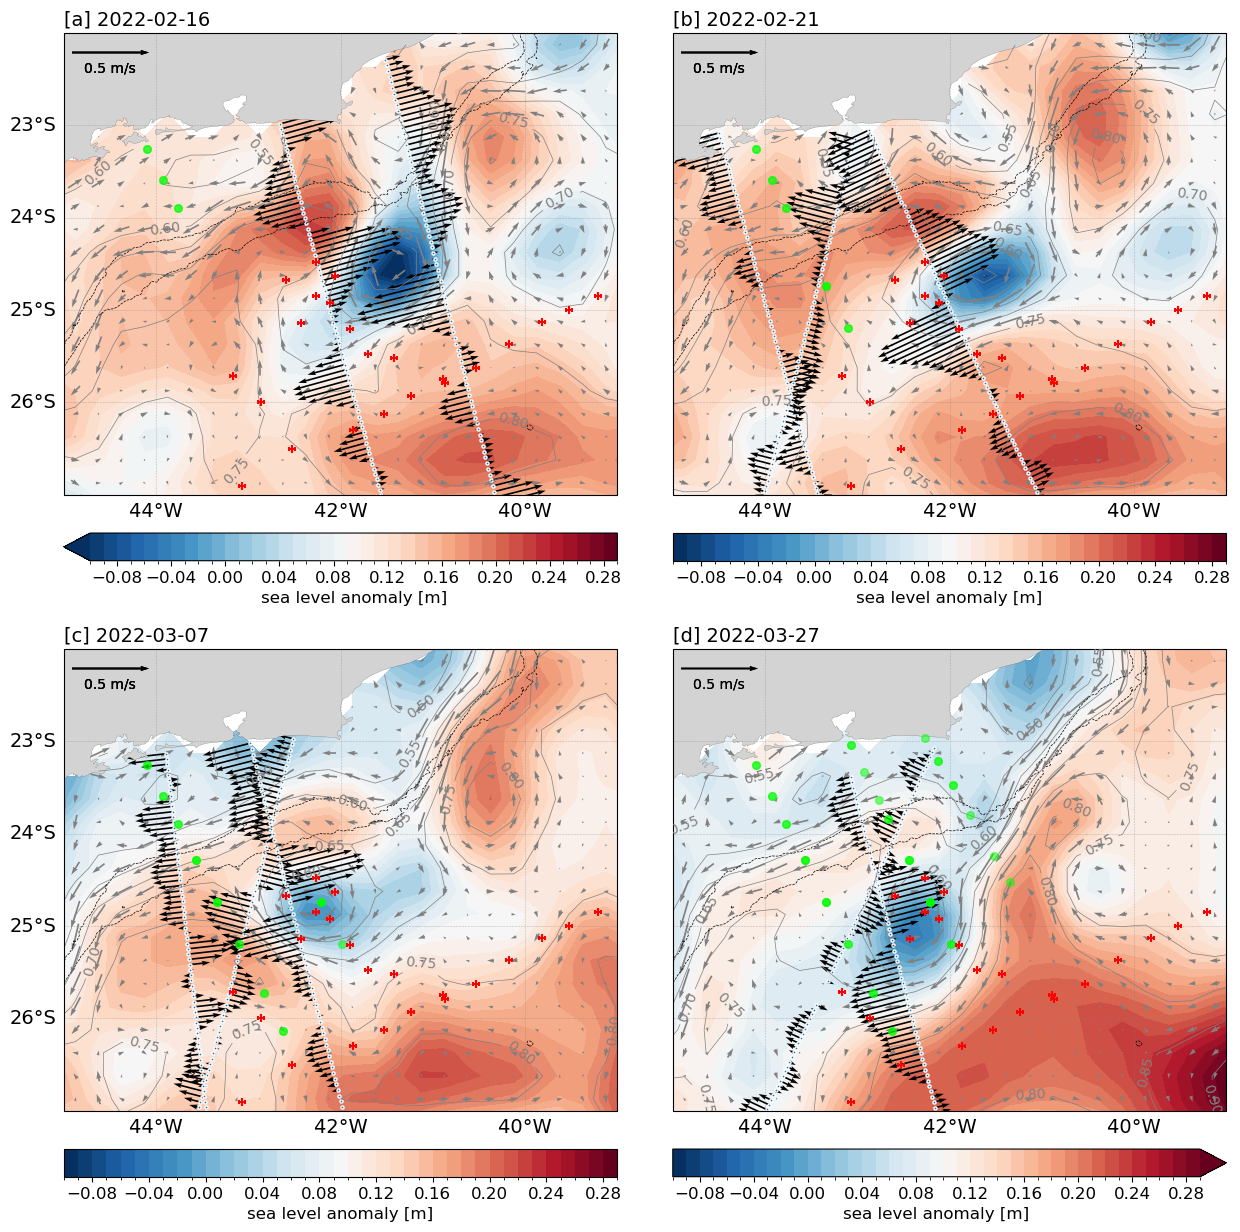

In [12]:
zoomed_extent= [-45, -39, -27, -22]

transect = build_transect(['2022-03-11', '2022-03-27'])

# selecting a zoomed region to plot the SLA from AVISO
ds_aviso_plot = ds_aviso.sel(longitude=slice(zoomed_extent[0]-0.5, zoomed_extent[1]+0.5),
                              latitude=slice(zoomed_extent[2]-0.5, zoomed_extent[3]+0.5))

days = list(tracks.keys())

# creating a letters list
letters = '[a] [b] [c] [d]'.split(' ')

fig,axes = subplots_structure(2, 2, (15,18), 4)

for n in range(4):
    drawlineleft = True if n in [0,2] else False
    day = days[n]
    t = f"{letters[n]} {day}"
    ax = axes[n]

    ax = make_map(ax=ax, facecolor='lightgray', deltax=2, deltay=1, drawlineleft=drawlineleft)
    ax.set_extent(zoomed_extent)

    bathy.depth.plot.contour(ax=ax,
                         levels=[-200, -1000], 
                         colors=('k'), linewidths=(0.5), linestyles=('--'))
    
    locs_plot = locs[locs['time'].astype('datetime64[ns]') <= pd.to_datetime(day)]
    ax.scatter(locs_plot['lon'], locs_plot['lat'], s=30, zorder=11, alpha=.5, marker='o', color='lime')
    
    ds_argo_plot = ds_argo.where(ds_argo['TIME'] <= pd.to_datetime(day), drop=True)
    ax.scatter(ds_argo['LONGITUDE'], ds_argo['LATITUDE'], color='r', zorder=11, s=30, marker='+')
    
    _plot_single_day(ax, day, tracks, ds_aviso=ds_aviso_plot, 
                     transect=None,
                     cbar_kwargs={'orientation': 'horizontal', 'location': 'bottom','pad': .05},
                     contourf_kwargs={"levels": np.arange(-0.1, 0.3, 0.01), 
                                      "cmap": "RdBu_r"}
                    )
    ax.set_title('')
    ax.set_title(t, loc='left', fontsize=14)
    
plt.subplots_adjust(hspace=0.0, wspace=.1)

fig.patch.set_alpha(1.0)
plt.subplots_adjust(hspace=-.2)
plt.savefig('../figures/manuscript/00_manuscript_geostrophic_fields.png', bbox_inches="tight", dpi=300)